In [2]:
from importlib import reload
import shutil
import sys
import multiprocessing as mp

import scipy
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner

sys.path.append("../python")
import pymodelica
reload(pymodelica)

<module 'pymodelica' from '/Users/Huss/thermal-models/TES_thermal_model/python/pymodelica.py'>

Fake data test of the MCMC on the 2-block model, fitting 7 parameters (alpha, beta, Tc, TES mass, K2, energy fraction, fall time).

# 1. Truth simulation

In [4]:
MODEL_CLASS = "System_2block"
MODEL_EXE_NAME = f"{MODEL_CLASS}_exe"
MODEL_FILE = f"../models/{MODEL_CLASS}.mo"
MODEL_BUILD_DIR = "../build"
MODEL_FILE_LIN = f"{MODEL_EXE_NAME}_linearized_model.py"

OVERRIDE_PARAMS = "../parameters/params_2block_HVeV_NFC.txt"
# 2 s is enough to reach equilibrium, and the pulse starts at 1 ms
EQUILIBRIUM_TIME = 2.0
EQUILIBRIUM_STEP = 2e-3
FINE_STOP_TIME = 2.6e-3
FINE_STEP_SIZE = 0.5e-6
TOLERANCE = 1e-8

# 40 eV x 0.5 = 20 eV deposited. Fraction is set to 0.5 so it's not at the edge of its prior
PULSE_ENERGY_EV = 40
PULSE_FRACTION = 0.5

# Sampling of the fake pulse
SAMPLE_RATE = 1.25e6
PRETRIGGER = 50e-6
POSTTRIGGER = 1.5e-3

N_PROCESSES = 8

In [5]:
run_info = pymodelica.run_model(
    model_exe=MODEL_EXE_NAME,
    build_dir=MODEL_BUILD_DIR,
    override_file=OVERRIDE_PARAMS,
    params={"Edep": PULSE_ENERGY_EV, "Edep_fractiontarget": PULSE_FRACTION},
    equilibrium_time=EQUILIBRIUM_TIME,
    coarse_step_size=EQUILIBRIUM_STEP,
    fine_stop_time=FINE_STOP_TIME,
    fine_step_size=FINE_STEP_SIZE,
    tolerance=TOLERANCE,
    solver="dassl",
    linearized_model_file=MODEL_FILE_LIN,
    keep_runs=True,
    verbose=False,
)

config = pymodelica.read_config(run_info["override_file"])

In [6]:
model = pymodelica.TESModel(run_info["linearized_model"],
                            MODEL_FILE,
                            run_info["init_result"],
                            config={},
                            f_min=1, f_max=1e6, f_scale="log", points=10_000)

T = 45.75 mK, R = 94.46 mOhm (R/Rn = 0.286), I = 2.487 uA, P = 0.5844 pW


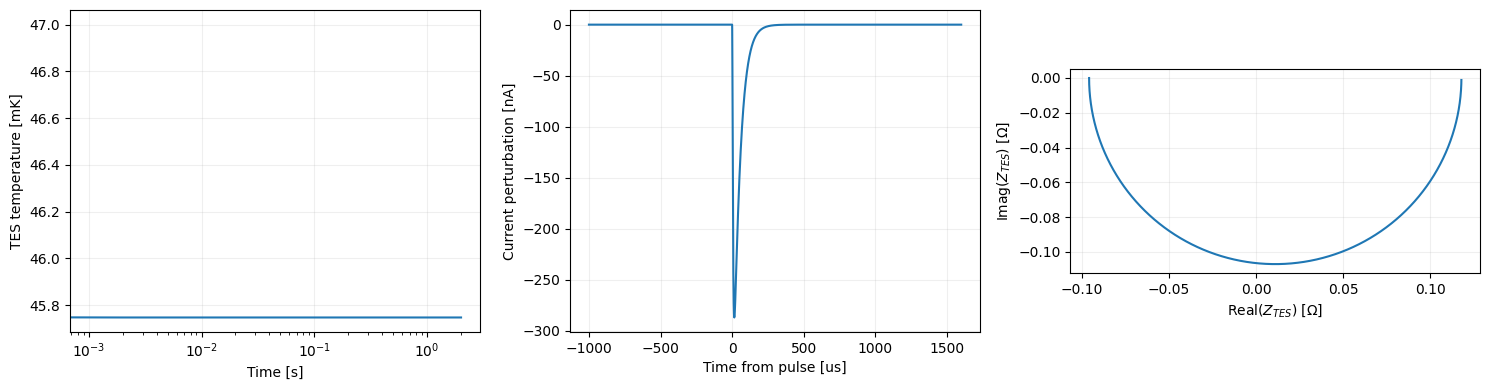

In [7]:
time_steps_init, data_init = pymodelica.load(run_info["init_result"])
time_steps, data = pymodelica.load(run_info["pulse_result"])

T0 = data_init["c1.T"][-1]
R0 = data_init["c1.R"][-1]
I0 = data_init["c1.i"][-1]
P0 = data_init["c1.P_Joule"][-1]
print(f"T = {T0*1e3:.4g} mK, R = {R0*1e3:.4g} mOhm (R/Rn = {R0/config['TES_Rn']:.3f}), I = {I0*1e6:.4g} uA, P = {P0*1e12:.4g} pW")

pulse_start = config["Edep_starttime"]
current_truth = data["c1.i"] - data["c1.i"][0]
Z_truth_grid = model.get_impedance()

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].plot(time_steps_init, data_init["c1.T"] * 1e3)
axs[0].set_xscale("log")
axs[0].set_xlabel("Time [s]")
axs[0].set_ylabel("TES temperature [mK]")
axs[1].plot((time_steps - pulse_start) * 1e6, current_truth * 1e9)
axs[1].set_xlabel("Time from pulse [us]")
axs[1].set_ylabel("Current perturbation [nA]")
axs[2].plot(Z_truth_grid.real, Z_truth_grid.imag)
axs[2].set_xlabel(r"Real($Z_{TES}$) [$\Omega$]")
axs[2].set_ylabel(r"Imag($Z_{TES}$) [$\Omega$]")
axs[2].set_aspect("equal", adjustable="box")
for ax in axs:
    ax.grid(alpha=0.2)
plt.tight_layout()

# 2. Smear the truth simulation into fake measurements

Bias power, pulse samples, and the real and imaginary impedance components are treated as independent Gaussian measurements. The pulse is sampled uniformly like a digitizer trace.

2003 data points (1938 pulse samples)


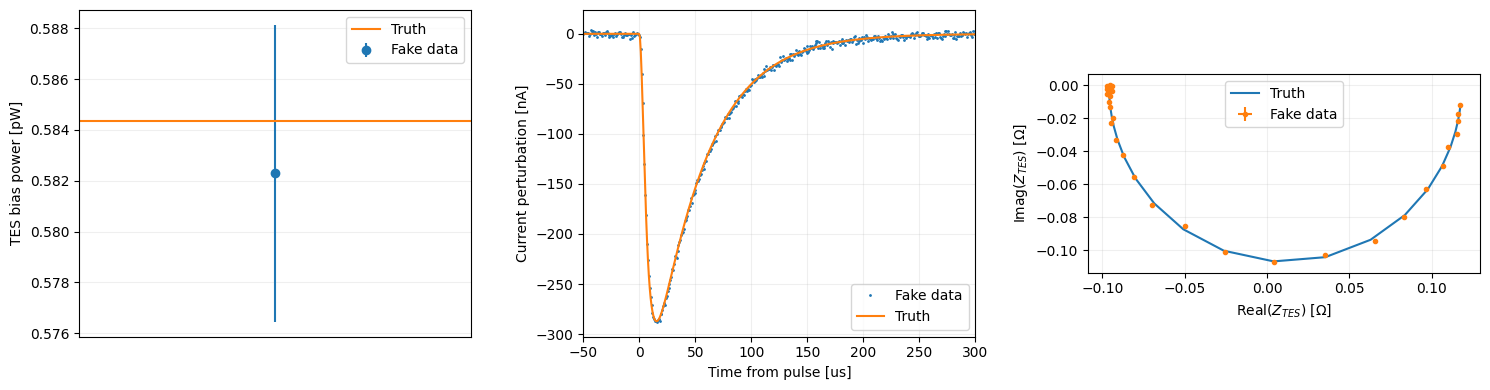

In [8]:
rng = np.random.default_rng(20261026)

# Bias power measurement, one percent uncertainty.
P_true = float(data_init["c1.P_Joule"][-1])
P_sigma = 0.01 * abs(P_true)
P_obs = float(P_true + rng.normal(scale=P_sigma))

# Pulse measurement, uniform sampling, 2 nA noise per sample.
t_obs = pulse_start + np.arange(-PRETRIGGER, POSTTRIGGER, 1 / SAMPLE_RATE)
I_true = np.interp(t_obs, time_steps, current_truth)
I_sigma = np.full_like(I_true, 2e-9)
I_obs = I_true + rng.normal(scale=I_sigma)

# Complex impedance measurement, independent errors on both components.
f_obs = np.logspace(1, 5, 32)
Z_true = (
    np.interp(f_obs, model.frequencies, Z_truth_grid.real)
    + 1j * np.interp(f_obs, model.frequencies, Z_truth_grid.imag)
)
Z_sigma = 0.01 * np.maximum(np.abs(Z_true), 0.02)
Zr_sigma = Z_sigma.copy()
Zi_sigma = Z_sigma.copy()
Z_obs = (
    Z_true.real + rng.normal(scale=Zr_sigma)
    + 1j * (Z_true.imag + rng.normal(scale=Zi_sigma))
)

N_DATA = 1 + len(I_obs) + 2 * len(Z_obs)
print(f"{N_DATA} data points ({len(I_obs)} pulse samples)")

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].errorbar([0], [P_obs * 1e12], yerr=[P_sigma * 1e12], fmt="o", label="Fake data")
axs[0].axhline(P_true * 1e12, color="C1", label="Truth")
axs[0].set_ylabel("TES bias power [pW]")
axs[0].set_xticks([])
axs[0].legend()
axs[1].plot((t_obs - pulse_start) * 1e6, I_obs * 1e9, ".", ms=2, label="Fake data")
axs[1].plot((t_obs - pulse_start) * 1e6, I_true * 1e9, label="Truth")
axs[1].set_xlim(-PRETRIGGER * 1e6, 300)
axs[1].set_xlabel("Time from pulse [us]")
axs[1].set_ylabel("Current perturbation [nA]")
axs[1].legend()
axs[2].plot(Z_true.real, Z_true.imag, label="Truth")
axs[2].errorbar(Z_obs.real, Z_obs.imag, xerr=Zr_sigma, yerr=Zi_sigma, fmt=".", label="Fake data")
axs[2].set_xlabel(r"Real($Z_{TES}$) [$\Omega$]")
axs[2].set_ylabel(r"Imag($Z_{TES}$) [$\Omega$]")
axs[2].set_aspect("equal", adjustable="box")
axs[2].legend()
for ax in axs:
    ax.grid(alpha=0.2)
plt.tight_layout()

# 3. Recover the parameters with MCMC

In [9]:
FIT_NAMES = ["TES_alpha", "TES_beta", "TES_Tc", "TES_m", "K2", "Edep_fractiontarget", "Edep_falltimetarget"]
truth_parameters = {name: config[name] for name in FIT_NAMES}

fit = pymodelica.TESMCMCFit(
    model_exe=MODEL_EXE_NAME,
    build_dir=MODEL_BUILD_DIR,
    full_model_file=MODEL_FILE,
    base_override_file=run_info["override_file"],
    equilibrium_time=EQUILIBRIUM_TIME,
    fine_stop_time=FINE_STOP_TIME,
    coarse_step_size=EQUILIBRIUM_STEP,
    fine_step_size=FINE_STEP_SIZE,
    tolerance=TOLERANCE,
    solver="dassl",
    linearized_model_file="linearized_model.py",
    tes_model_kwargs={"frequencies": f_obs},
    keep_runs=False,
    verbose=False,
)

# Start away from the truth. Tc and K2 are moved together so K2*Tc^5 (the bias power)
# stays about the same and the TES is still in the transition.
initial_parameters = {
    "TES_alpha": 0.8 * truth_parameters["TES_alpha"],
    "TES_beta": 1.4 * truth_parameters["TES_beta"],
    "TES_Tc": 1.02 * truth_parameters["TES_Tc"],
    "TES_m": 1.25 * truth_parameters["TES_m"],
    "K2": 0.9 * truth_parameters["K2"],
    "Edep_fractiontarget": 0.6,
    "Edep_falltimetarget": 1.5 * truth_parameters["Edep_falltimetarget"],
}

fit.set_parameters(
    FIT_NAMES,
    priors={
        "TES_alpha": stats.uniform(10.0, 70.0),
        "TES_beta": stats.uniform(0.0, 2.0),
        "TES_Tc": stats.uniform(0.042, 0.008),
        "TES_m": stats.loguniform(truth_parameters["TES_m"] / 4, truth_parameters["TES_m"] * 4),
        "K2": stats.loguniform(truth_parameters["K2"] / 4, truth_parameters["K2"] * 4),
        "Edep_fractiontarget": stats.uniform(0.1, 0.9),
        "Edep_falltimetarget": stats.loguniform(truth_parameters["Edep_falltimetarget"] / 4, truth_parameters["Edep_falltimetarget"] * 4),
    },
    initial=initial_parameters,
    transform={"TES_Tc": "log", "TES_m": "log", "K2": "log", "Edep_falltimetarget": "log"},
)

fit.set_measurements({
    "bias_power": {
        "value": P_obs,
        "sigma": P_sigma,
        "model_key": "c1.P_Joule",
    },
    "pulse": {
        "time": t_obs,
        "values": I_obs,
        "sigma": I_sigma,
        "model_key": "c1.i",
        "baseline": "subtract_initial",
    },
    "impedance": {
        "frequencies": f_obs,
        "values": Z_obs,
        "sigma_real": Zr_sigma,
        "sigma_imag": Zi_sigma,
        "observable": "impedance",
    },
})

In [10]:
def params_to_theta(params):
    theta = []
    for name in fit.parameter_names:
        if fit.transforms[name] == "log":
            theta.append(np.log(params[name]))
        else:
            theta.append(params[name])
    return np.array(theta)

# Check before running: at the truth, chi2 of each block should be about its number of points
for label, params in [("truth", truth_parameters), ("start", initial_parameters)]:
    log_like = fit.log_likelihood(params_to_theta(params))
    print(label, f"log L = {log_like:.1f}", fit.last_chi2, "error:", fit.last_error)

truth log L = -1034.1 {'bias_power': 0.12509732635984264, 'pulse': 2007.4523748231013, 'impedance': 60.65224622100596} error: None
start log L = -51687.8 {'bias_power': 0.2463750907037024, 'pulse': 85572.10882639543, 'impedance': 17803.193681150784} error: None


In [11]:
N_WALKERS = 32
N_STEPS = 3000
CHAIN_FILE = f"{MODEL_BUILD_DIR}/2block_mcmc_chain.h5"
ndim = len(FIT_NAMES)

def log_probability(theta):
    # Wrapper so the pool doesn't have to pickle the fit object
    return fit.log_probability(theta)

# Walkers start in a ~1% ball around the starting point
np.random.seed(20261026)
center = params_to_theta(initial_parameters)
is_log = np.array([fit.transforms[name] == "log" for name in FIT_NAMES])
scale = np.where(is_log, 0.01, 0.01 * np.abs(center))
initial_state = center + scale * np.random.randn(N_WALKERS, ndim)

with mp.Pool(N_PROCESSES) as pool:
    initial_log_prob = np.array(pool.map(log_probability, initial_state))
print("Finite starting points:", np.isfinite(initial_log_prob).sum(), "/", N_WALKERS)

Finite starting points: 32 / 32


In [12]:
# The chain is saved to CHAIN_FILE as it runs. reset() erases the file,
#so don't rerun this cell just to look at the results.
backend = emcee.backends.HDFBackend(CHAIN_FILE)
backend.reset(N_WALKERS, ndim)

with mp.Pool(N_PROCESSES) as pool:
    sampler = emcee.EnsembleSampler(N_WALKERS, ndim, log_probability, pool=pool, backend=backend)
    sampler.run_mcmc(initial_state, N_STEPS, progress=True)

print("Mean acceptance fraction:", np.mean(sampler.acceptance_fraction))

You must install the tqdm library to use progress indicators with emcee


Mean acceptance fraction: 0.39286458333333335


# 4. Results

Autocorrelation time [steps]: {'TES_alpha': np.float64(136.4), 'TES_beta': np.float64(184.7), 'TES_Tc': np.float64(140.7), 'TES_m': np.float64(97.9), 'K2': np.float64(142.5), 'Edep_fractiontarget': np.float64(99.4), 'Edep_falltimetarget': np.float64(39.7)}


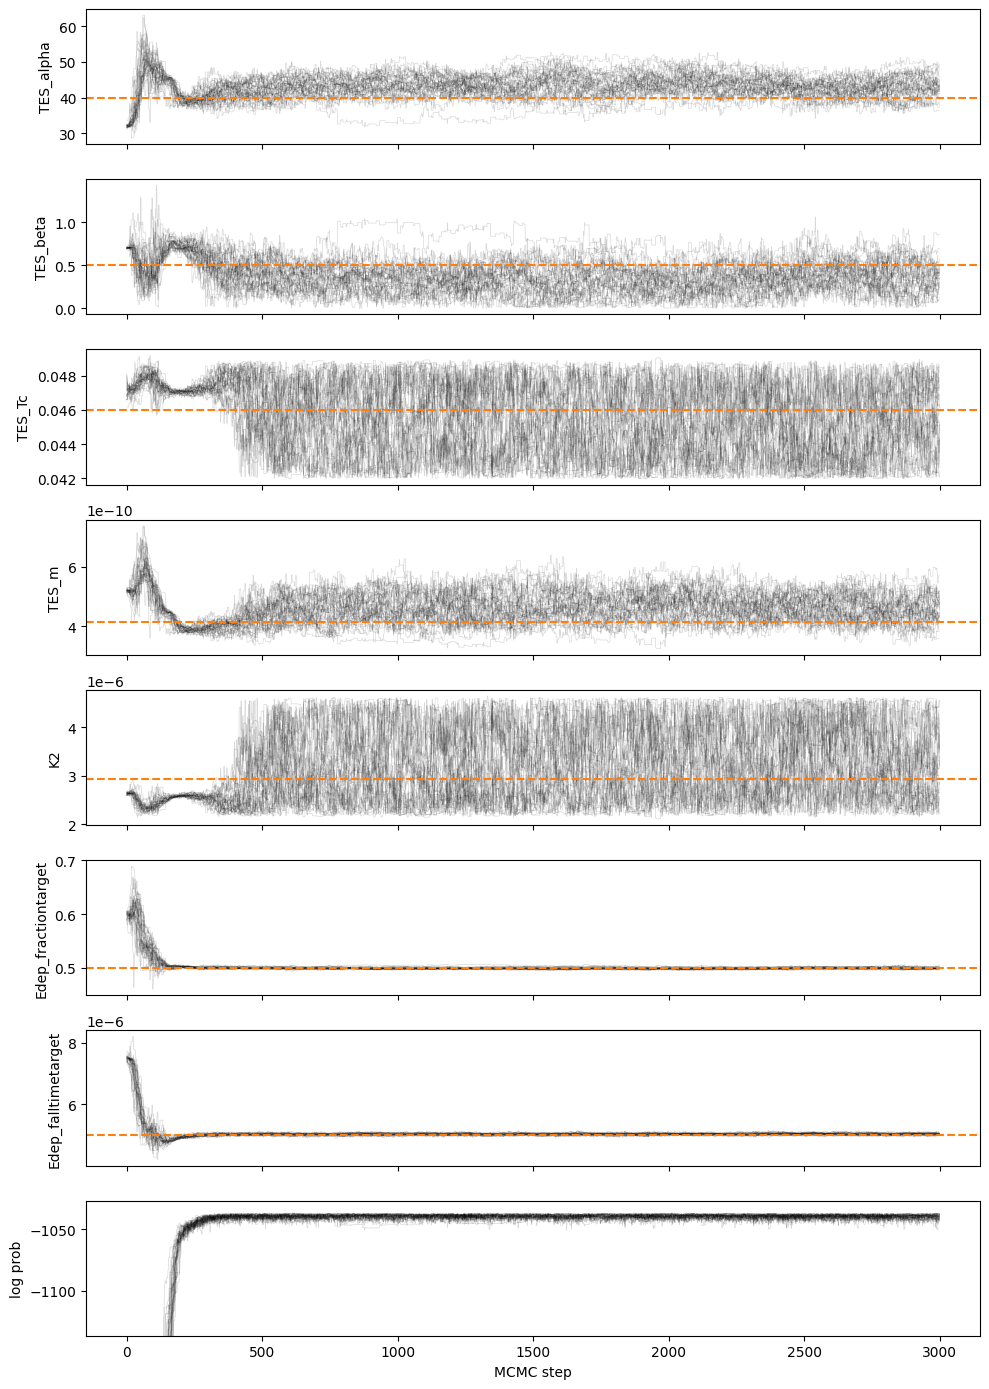

In [14]:
backend = emcee.backends.HDFBackend(CHAIN_FILE, read_only=True)
theta_chain = backend.get_chain()
log_prob_chain = backend.get_log_prob()

physical_chain = theta_chain.copy()
physical_chain[:, :, is_log] = np.exp(theta_chain[:, :, is_log])

tau = backend.get_autocorr_time(tol=0)
print("Autocorrelation time [steps]:", dict(zip(FIT_NAMES, np.round(tau, 1))))

fig, axs = plt.subplots(ndim + 1, 1, figsize=(10, 14), sharex=True)
for i, name in enumerate(FIT_NAMES):
    axs[i].plot(physical_chain[:, :, i], "k", alpha=0.15, lw=0.5)
    axs[i].axhline(truth_parameters[name], color="C1", linestyle="--")
    axs[i].set_ylabel(name)
axs[-1].plot(log_prob_chain, "k", alpha=0.15, lw=0.5)
axs[-1].set_ylim(log_prob_chain.max() - 100, log_prob_chain.max() + 10)
axs[-1].set_ylabel("log prob")
axs[-1].set_xlabel("MCMC step")
plt.tight_layout()

Burn-in 554 steps, thin by 19, 4128 samples
TES_alpha: 43.31 +3 -2.8 (truth 40, pull +1.13)
TES_beta: 0.3412 +0.17 -0.17 (truth 0.5, pull -0.94)
TES_Tc: 0.04533 +0.0022 -0.0024 (truth 0.046, pull -0.29)
TES_m: 4.615e-10 +5.5e-11 -4.8e-11 (truth 4.16e-10, pull +0.88)
K2: 3.141e-06 +9.8e-07 -6.7e-07 (truth 2.92e-06, pull +0.27)
Edep_fractiontarget: 0.4994 +0.0017 -0.0016 (truth 0.5, pull -0.35)
Edep_falltimetarget: 5.026e-06 +3.2e-08 -3.4e-08 (truth 5e-06, pull +0.80)


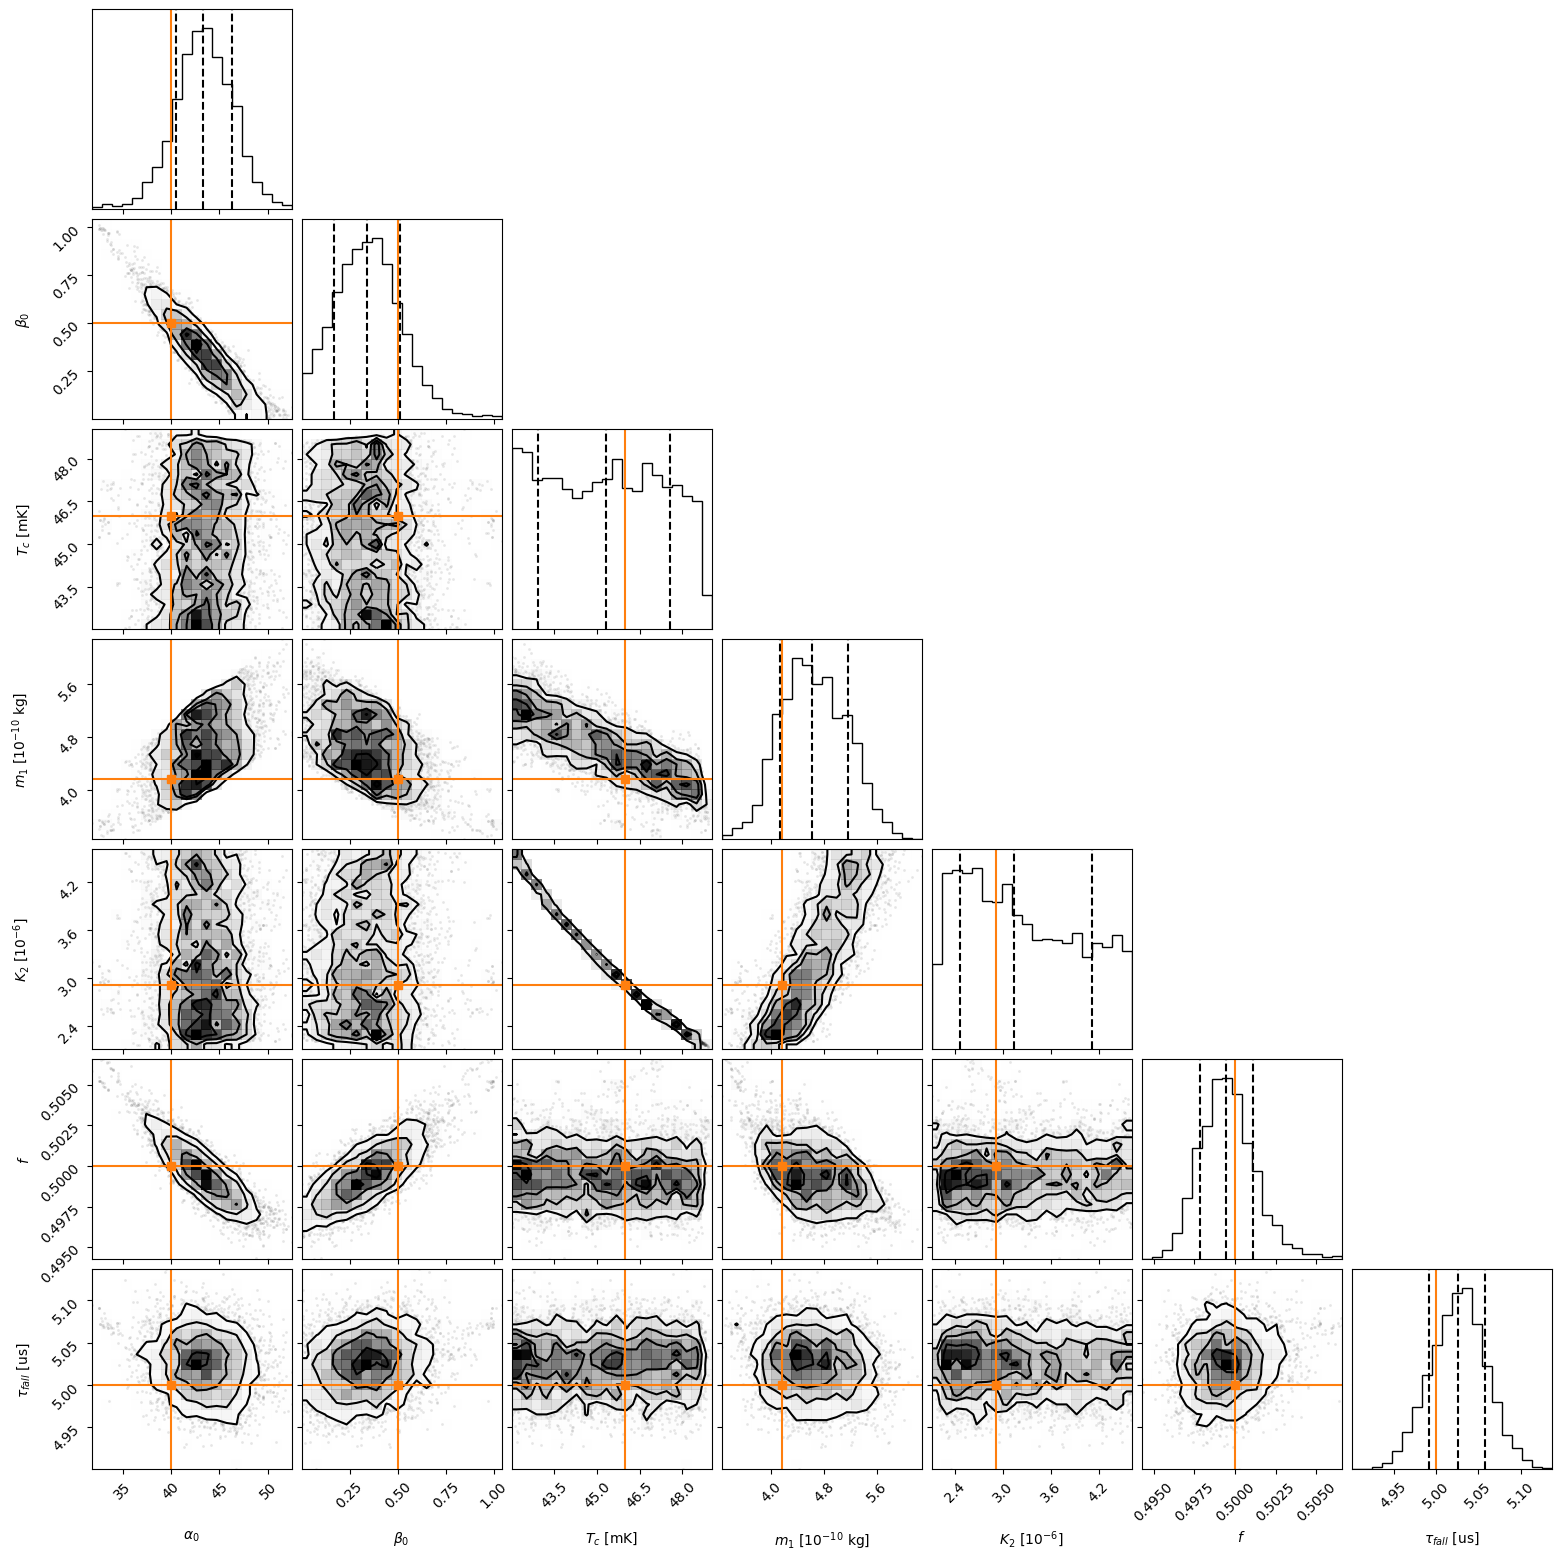

In [15]:
BURN_IN = int(3 * np.max(tau))
THIN = int(0.5 * np.min(tau))
flat_samples = physical_chain[BURN_IN::THIN].reshape(-1, ndim)
print(f"Burn-in {BURN_IN} steps, thin by {THIN}, {len(flat_samples)} samples")

for i, name in enumerate(FIT_NAMES):
    lower, median, upper = np.percentile(flat_samples[:, i], [16, 50, 84])
    truth = truth_parameters[name]
    pull = (median - truth) / (0.5 * (upper - lower))
    print(f"{name}: {median:.4g} +{upper - median:.2g} -{median - lower:.2g} (truth {truth:.4g}, pull {pull:+.2f})")

labels = [r"$\alpha_0$", r"$\beta_0$", r"$T_c$ [mK]", r"$m_1$ [$10^{-10}$ kg]", r"$K_2$ [$10^{-6}$]", r"$f$", r"$\tau_{fall}$ [us]"]
scales = np.array([1, 1, 1e3, 1e10, 1e6, 1, 1e6])
truths = np.array([truth_parameters[name] for name in FIT_NAMES]) * scales

fig = corner.corner(flat_samples * scales, labels=labels, truths=truths, truth_color="C1", quantiles=[0.16, 0.5, 0.84])
plt.show()

Highest-posterior parameters: {'TES_alpha': 43.489029095983994, 'TES_beta': 0.3215391154481795, 'TES_Tc': 0.04795370588763487, 'TES_m': 4.1338749780896517e-10, 'K2': 2.3710269226155184e-06, 'Edep_fractiontarget': 0.49929190241740184, 'Edep_falltimetarget': 5.023456186856772e-06}
chi2 = 2061.3 for 1996 dof (chi2/dof = 1.033) {'bias_power': 0.08537085819826261, 'pulse': 2001.0848852583877, 'impedance': 60.09691578865343}


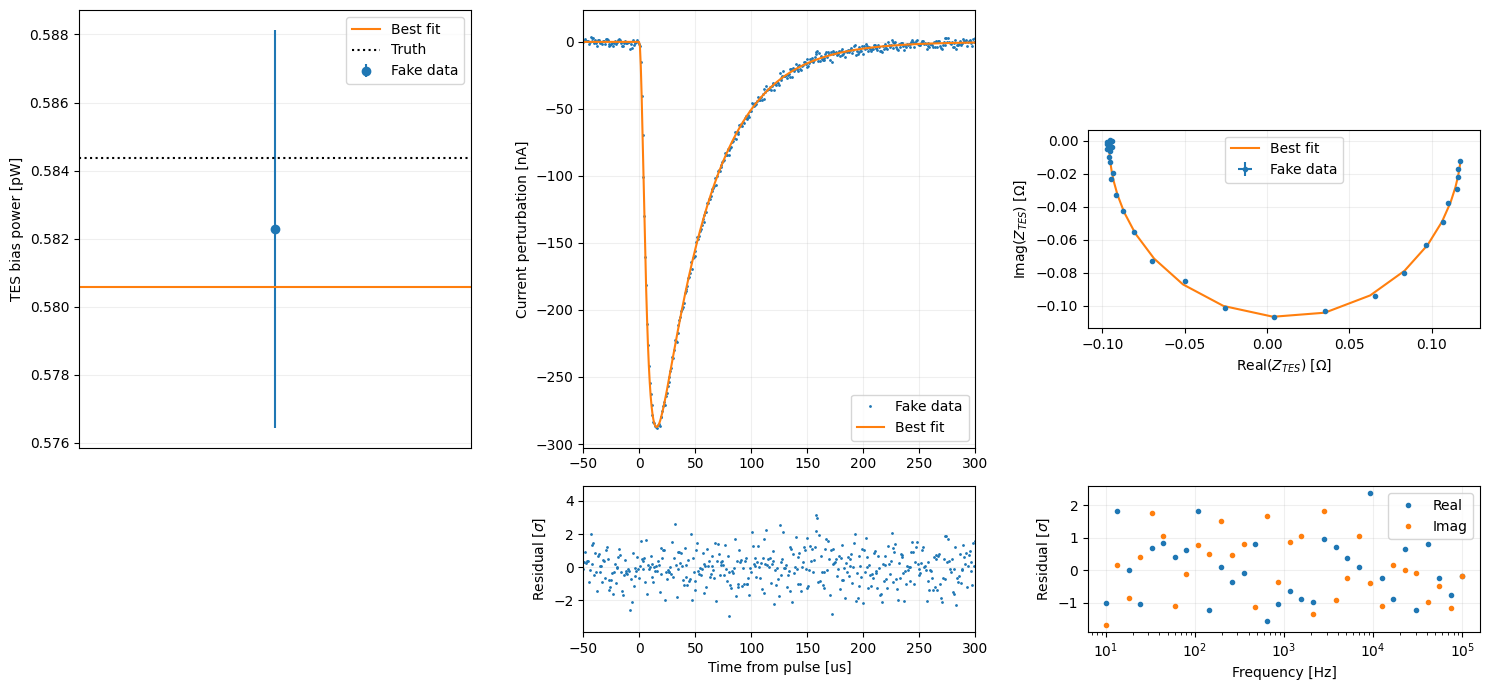

In [16]:
flat_theta = backend.get_chain(discard=BURN_IN, flat=True)
flat_log_probability = backend.get_log_prob(discard=BURN_IN, flat=True)
best_theta = flat_theta[np.argmax(flat_log_probability)]
best_parameters = fit.theta_to_params(best_theta)
print("Highest-posterior parameters:", best_parameters)

fit.log_likelihood(best_theta)
chi2 = sum(fit.last_chi2.values())
print(f"chi2 = {chi2:.1f} for {N_DATA - ndim} dof (chi2/dof = {chi2 / (N_DATA - ndim):.3f})", fit.last_chi2)

best_result = fit.run_model(best_parameters)
if best_result is None:
    raise RuntimeError("Best-fit simulation failed") from fit.last_error

try:
    _, best_init_data = pymodelica.load(best_result["init_result"])
    best_pulse_time, best_pulse_data = pymodelica.load(best_result["pulse_result"])
    best_current = best_pulse_data["c1.i"] - best_pulse_data["c1.i"][0]
    best_current_obs = np.interp(t_obs, best_pulse_time, best_current)
    best_model = pymodelica.TESModel(
        best_result["linearized_model"],
        MODEL_FILE,
        best_result["init_result"],
        config={},
        frequencies=f_obs,
    )
    Z_best = best_model.get_impedance()
    P_best = float(best_init_data["c1.P_Joule"][-1])

    fig, axs = plt.subplots(2, 3, figsize=(15, 7), gridspec_kw={"height_ratios": [3, 1]})
    axs[0, 0].errorbar([0], [P_obs * 1e12], yerr=[P_sigma * 1e12], fmt="o", label="Fake data")
    axs[0, 0].axhline(P_best * 1e12, color="C1", label="Best fit")
    axs[0, 0].axhline(P_true * 1e12, color="k", linestyle=":", label="Truth")
    axs[0, 0].set_ylabel("TES bias power [pW]")
    axs[0, 0].set_xticks([])
    axs[0, 0].legend()
    axs[1, 0].axis("off")

    t_us = (t_obs - pulse_start) * 1e6
    axs[0, 1].plot(t_us, I_obs * 1e9, ".", ms=2, label="Fake data")
    axs[0, 1].plot(t_us, best_current_obs * 1e9, color="C1", label="Best fit")
    axs[0, 1].set_xlim(-PRETRIGGER * 1e6, 300)
    axs[0, 1].set_ylabel("Current perturbation [nA]")
    axs[0, 1].legend()
    axs[1, 1].plot(t_us, (I_obs - best_current_obs) / I_sigma, ".", ms=2)
    axs[1, 1].set_xlim(-PRETRIGGER * 1e6, 300)
    axs[1, 1].set_xlabel("Time from pulse [us]")
    axs[1, 1].set_ylabel(r"Residual [$\sigma$]")

    axs[0, 2].errorbar(Z_obs.real, Z_obs.imag, xerr=Zr_sigma, yerr=Zi_sigma, fmt=".", label="Fake data")
    axs[0, 2].plot(Z_best.real, Z_best.imag, color="C1", label="Best fit")
    axs[0, 2].set_xlabel(r"Real($Z_{TES}$) [$\Omega$]")
    axs[0, 2].set_ylabel(r"Imag($Z_{TES}$) [$\Omega$]")
    axs[0, 2].set_aspect("equal", adjustable="box")
    axs[0, 2].legend()
    axs[1, 2].semilogx(f_obs, (Z_obs.real - Z_best.real) / Zr_sigma, ".", label="Real")
    axs[1, 2].semilogx(f_obs, (Z_obs.imag - Z_best.imag) / Zi_sigma, ".", label="Imag")
    axs[1, 2].set_xlabel("Frequency [Hz]")
    axs[1, 2].set_ylabel(r"Residual [$\sigma$]")
    axs[1, 2].legend()
    for ax in axs.flat:
        ax.grid(alpha=0.2)
    plt.tight_layout()
finally:
    if not fit.keep_runs:
        shutil.rmtree(best_result["run_dir"], ignore_errors=True)